# Projection-Cartographique-CASSIOPE-FAI
***

**Tutoriel :** Ce tutoriel explique comment visualiser les données de la caméra FAI avec diverses projections cartographiques  
**Mission et Instrument :** FAI (Fast Auroral Imager) sur CASSIOPE      
**Objectif astronomique :** Émissions aurorales    
**Outil principal :** Script Python3       
**Niveau du tutoriel :** Intermédiaire

Des images de la Terre peuvent être difficiles à visualiser, surtout les pôles. Il existe une variété de projections cartographiques pour visualiser des images réalistes du globe. L'objectif de ce tutoriel est de tester plusieurs projections cartographiques du module *Basemap* de *Matplotlib* avec une image du FAI. Ce tutoriel inclut deux visualisations :

1. Une image agrandie de la photo prise par le FAI ;
2. Une carte générale avec l'image du FAI agrandie dans une fenêtre.

Voici une liste de [projections cartographiques](https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html) supportées par *Cartopy*.

## Bibliothèque

Le script qui suit utilise

* *numpy* : opération mathématique et array multidimentionnel
* *h5py* : ouverture de fichier .h5
* *pandas* : structure de dataframe
* *matplotlib* : tracer des figures
* *cartopy* : tracer des cartes

In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import h5py

## Carte agrandie

On commence avec une simple fonction pour identifier les latitudes et longitudes de la carte selon la projection. On va utiliser cette même fonction pour la seconde visualisation.

In [70]:
# Fonction traçant une carte agrandie
# Paramètres
# ax : l'axe utilisé pour créer la carte (Axe)
# lon : les longitudes de l'image (array of float)
# lat : les latitudes de l'image (array of float)
# proj : l'id de la projection cartographique (string)
# interPara : l'intervalle entre les graduations des parallèles (float)
# interMeri : l'intervalle entre les graduations des méridiens (float)
# lonmargins : les marges sur l'axe des x (longitude) (float)
# latmargins : les marges sur l'axe des y (latitude) (float)
# Returns the map
def createZoomedMap(lon,lat,proj,interPara,interMeri,lonmargins,latmargins):
    
    # On veut une petite carte
    width=400000
    height=200000
    minlon = np.nanmin(lon)-lonmargins
    maxlon = np.nanmax(lon)+lonmargins
    minlat = np.nanmin(lat)-latmargins
    maxlat = np.nanmax(lat)+latmargins
    lat_0=lat[139][127]
    lon_0=lon[139][127]
    
    # Albers Equal Area
    plt.figure(figsize=(6, 6))
    if(proj in ['aea']):
        ax = plt.axes(projection=ccrs.AlbersEqualArea(lon_0, lat_0))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Azimuthal Equidistant
    elif(proj in ['aeqd']):
        ax = plt.axes(projection=ccrs.AzimuthalEquidistant(central_latitude=90))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Equidistant Conic
    elif(proj in ['eqdc']):
        ax = plt.axes(projection=ccrs.EquidistantConic(lon_0, lat_0))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Lambert Conformal
    elif(proj in ['lcc']):
        ax = plt.axes(projection=ccrs.LambertConformal(lon_0, lat_0))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Lambert Azimuthal Equal Area
    elif(proj in ['laea','cyl']):
        ax = plt.axes(projection=ccrs.LambertCylindrical())
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Goode Homolosine
    elif(proj in ['goode']):
        ax = plt.axes(projection=ccrs.InterruptedGoodeHomolosine(emphasis='land'))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Stereographic
    elif(proj in ['stere']):
        ax = plt.axes(projection=ccrs.Stereographic(lon_0, lat_0))
        ax.coastlines(resolution='110m')
        ax.gridlines()
        ax.stock_img()
        ax.set_global()
    # Orthographic
    elif(proj in ['ortho']):
        ax = plt.axes(projection=ccrs.Orthographic(lon_0, lat_0))
        ax.coastlines(resolution='110m')
        ax.add_feature(cartopy.feature.OCEAN, zorder=0)
        ax.add_feature(cartopy.feature.LAND, zorder=0, edgecolor='black')
        ax.set_global()
        ax.gridlines()
    # Near-Sided Perspective
    elif(proj in ['nsper']):
        ax = plt.axes(projection=ccrs.NearsidePerspective(lon_0))
        ax.coastlines(resolution='110m')
        ax.add_feature(cartopy.feature.OCEAN, zorder=0)
        ax.add_feature(cartopy.feature.LAND, zorder=0, edgecolor='black')
        ax.set_global()
        ax.gridlines()
    # For other projections
    else:
        ax = plt.axes(projection=ccrs.Mollweide())
        ax.stock_img()
        ax.set_global()
    
    return (ax)

Maintenant, voyons comment la carte avec l'image est tracée.

In [72]:
# Fonction traçant l'image du FAI sur une carte agrandie 
# Paramètres :
# file : le répertoire du fichier (string)
# proj : l'id de la projection Basemap (string)
# title : le titre de la figure (string)
# pct : le % top des valeurs qui sera en blanc (default=0.01) (float)
# interPara : l'intervalle entre les étiquettes des parallèles (default=2.) (float)
# interMeri : l'intervalle entre les étiquettes des méridiens (default=5.)
# lonmargins : les marges sur l'axe des x (longitude) (float)
# latmargins : les marges sur l'axe des y (latitude) (float)
# Returne rien
def plotZoomedMap(file, proj, title, lonmargins=2., latmargins=1., pct=0.01, interPara=1., interMeri=2.):
    
    # Liste des projections supportées par ce code
    supportedProjection = ['ortho','nsper','cyl','mill', 'goode', 'stere', 'aea',
                           'eqdc','aeqd','lcc','laea']
    # Si c'est une projection différente, arrêt
    if(proj not in supportedProjection):
        print("\nCette projection n'est pas supportée")
        return()
    
    # Ouvrir le fichier et extraire les latitudes, les longitudes, l'image et le facteur de conversion
    with h5py.File(file, 'r') as f:
        keys = f.attrs.keys()
        values = f.attrs.values()
        attributes = pd.DataFrame(values, keys)
        conversion = int(attributes.loc['DN to Rayleigh Conversion Factor (R/DN/s)'])
        date_utc = str(attributes.loc['UTC'])
        image = np.array(f.get('FAI Image'))/conversion
        lat = np.array(f.get('Pixel Latitudes'))
        lon = np.array(f.get('Pixel Longitudes'))
    
    # Retirer la dernière ligne et colonne, puisque qu'elles indiquent
    # seulement le coin en bas à droite de l'image
    lat = np.delete(lat,lat.shape[0]-1,0) 
    lat = np.delete(lat,lat.shape[1]-1,1) 
    lon = np.delete(lon,lon.shape[0]-1,0) 
    lon = np.delete(lon,lon.shape[1]-1,1)
    
    # Ajuster la date
    date_utc = date_utc[4:24].replace('T', ' ')
    
    # Créer la carte
    m = createZoomedMap(lon,lat,proj,interPara,interMeri,lonmargins,latmargins)
    m.plot(lon[139][127], lat[139][127],
         color='magenta', linewidth=2, marker='o',
         transform=ccrs.Geodetic(),
         )
    
    # Afficher la carte
    fig = plt.figure(figsize=(8, 8))
    img_extent = (lon[139][127]-6.4, lon[139][127]+6.4, lat[139][127]-8.4, lat[139][127]+8.4)
    zoom_ax = plt.axes(projection=ccrs.PlateCarree())
    plt.title(title + '\n' + date_utc + '\nLatitude: {:.2f}'.format(lat[139][127]) + '\nLongitude: {:.2f}'.format(lon[139][127]))

    # Créer l'axe et définir les marges
    zoom_ax.set_xmargin(0.05)
    zoom_ax.set_ymargin(0.10)

    # Ajouter l'image
    zoom_ax.imshow(image, origin='lower', extent=img_extent, transform=ccrs.PlateCarree())
    zoom_ax.coastlines(resolution='50m', color='black', linewidth=1)
    plt.show()
    
    return()    

Testons le tout!

In [73]:
file='FAI_lv1_NIR_20190501_183357_183357_6.0.0.h5'

message
  


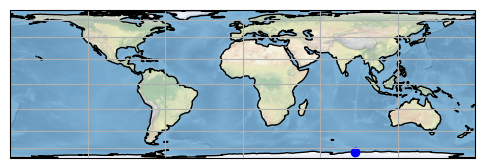

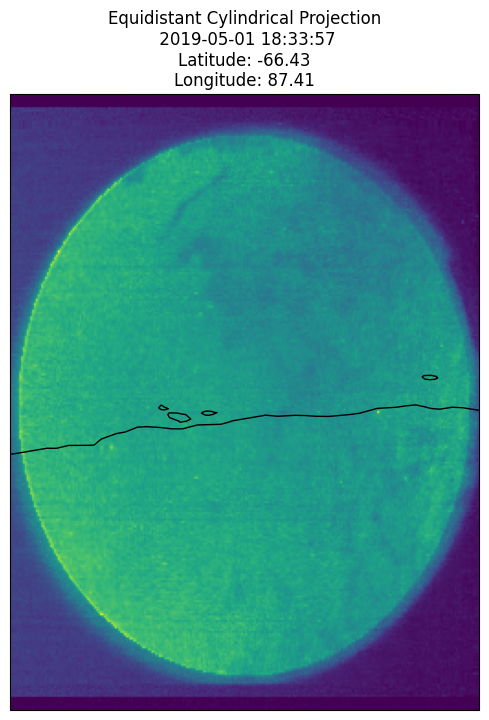

()

In [137]:
plotZoomedMap(file,'cyl', 'Equidistant Cylindrical Projection')

message
  


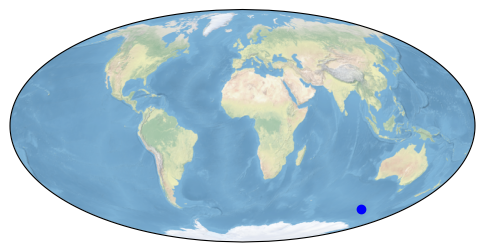

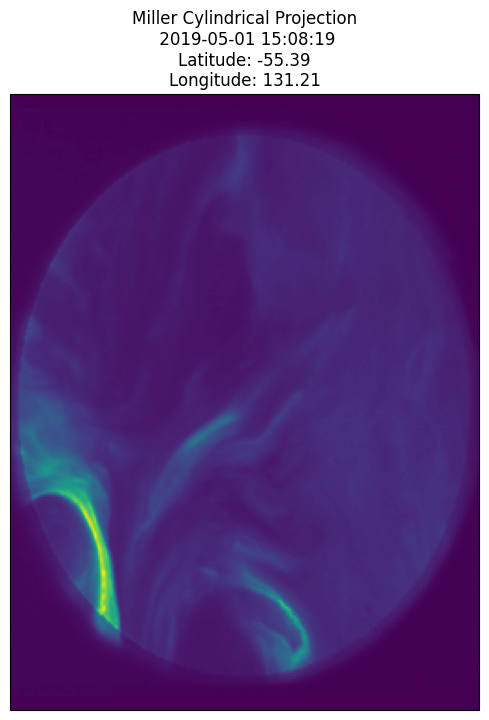

()

In [138]:
file='FAI_lv1_NIR_20190501_150819_150819_6.0.0.h5'
plotZoomedMap(file,'mill', 'Miller Cylindrical Projection')

message
  


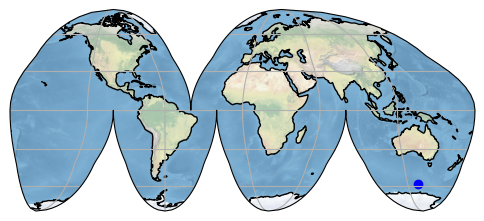

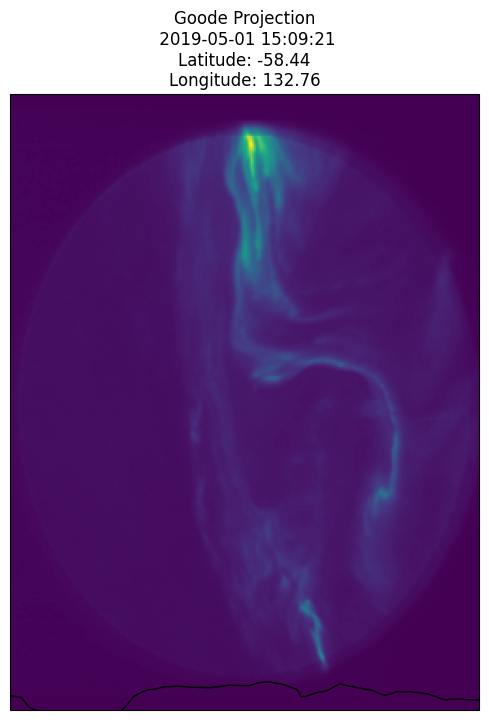

()

In [139]:
file='FAI_lv1_NIR_20190501_150921_150921_6.0.0.h5'
plotZoomedMap(file, 'goode', 'Goode Projection')

message
  


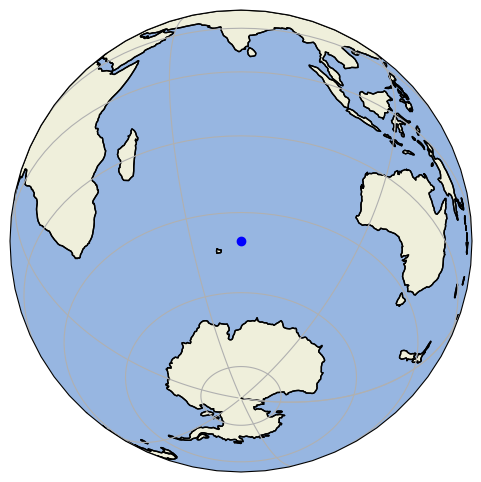

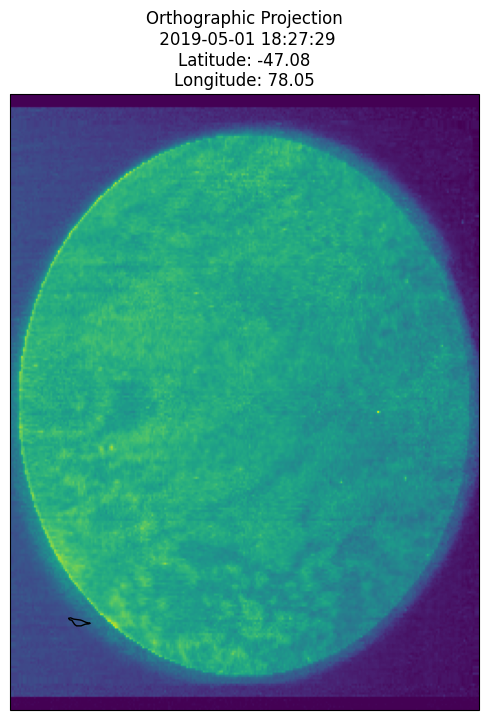

()

In [140]:
file='FAI_lv1_NIR_20190501_182729_182729_6.0.0.h5'
plotZoomedMap(file, 'ortho', 'Orthographic Projection')

message
  


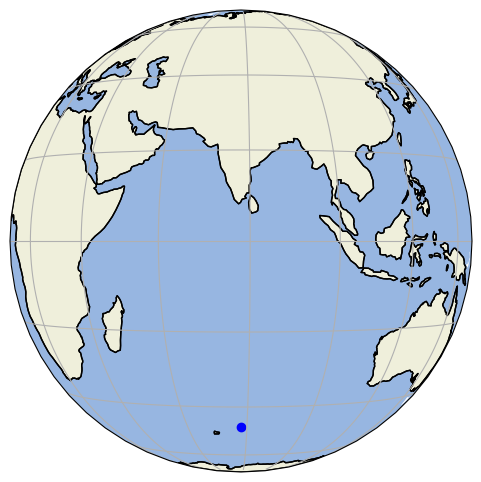

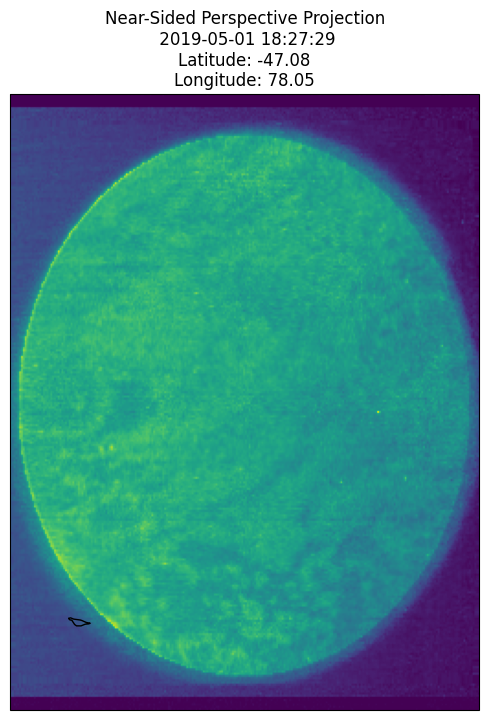

()

In [141]:
plotZoomedMap(file, 'nsper', 'Near-Sided Perspective Projection')

message
  


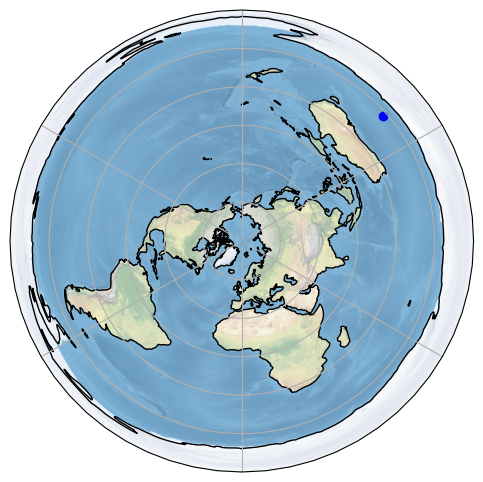

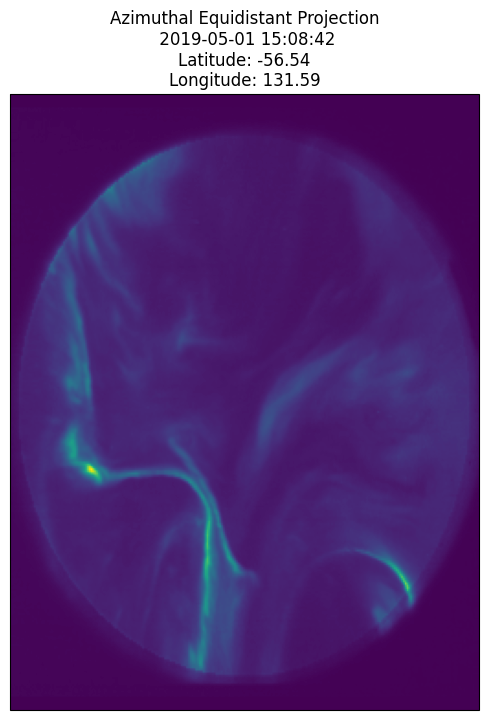

()

In [142]:
file='FAI_lv1_NIR_20190104_070011_070011_6.0.0.h5'
plotZoomedMap(file, 'aeqd', 'Azimuthal Equidistant Projection')

**Cartes du globe**

message
  


Stereo Projection


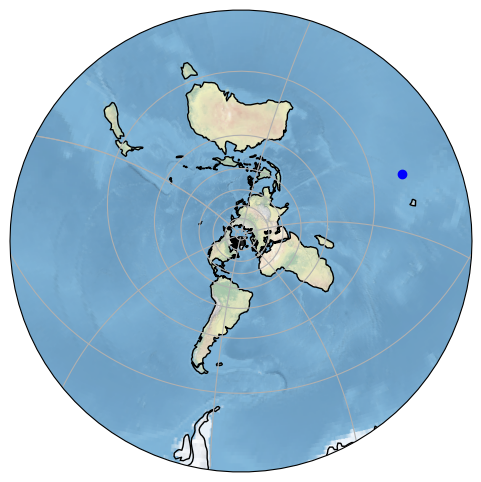

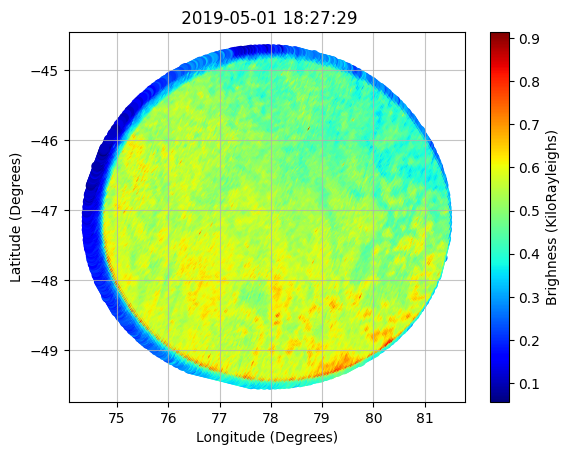

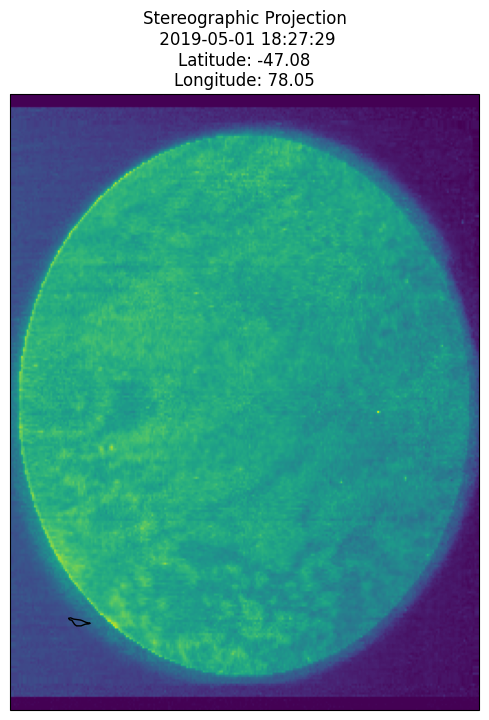

()

In [104]:
file='FAI_lv1_NIR_20190501_182729_182729_6.0.0.h5'
plotZoomedMap(file, 'stere', 'Stereographic Projection')

message
  


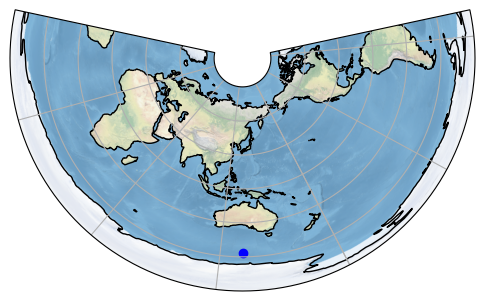

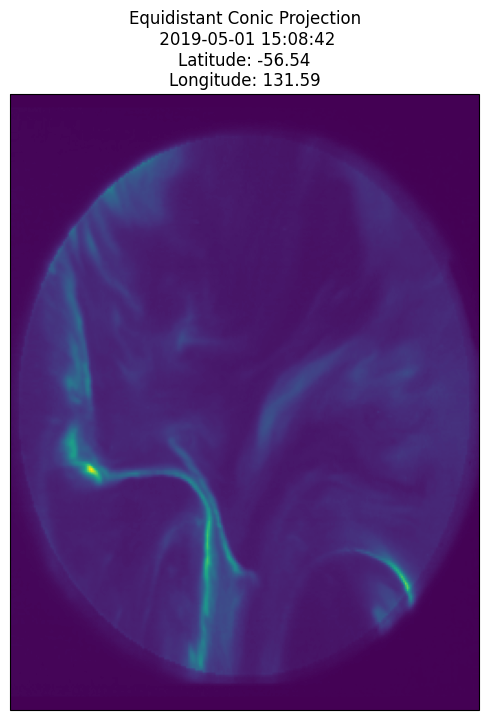

()

In [143]:
plotZoomedMap(file, 'eqdc', 'Equidistant Conic Projection')

message
  


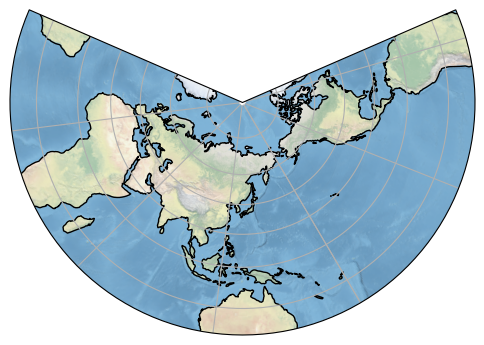

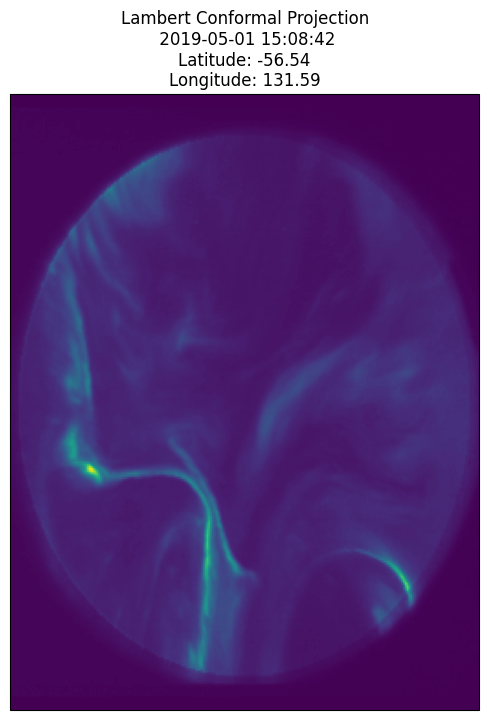

()

In [144]:
plotZoomedMap(file, 'lcc', 'Lambert Conformal Projection')

message
  


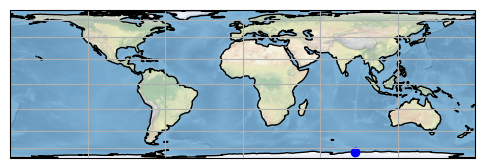

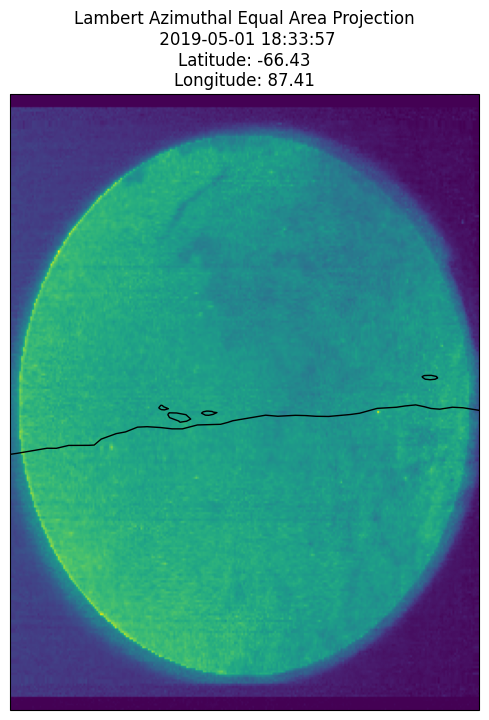

()

In [145]:
file='FAI_lv1_NIR_20190104_070011_070011_6.0.0.h5'
plotZoomedMap(file, 'laea', 'Lambert Azimuthal Equal Area Projection')

message
  


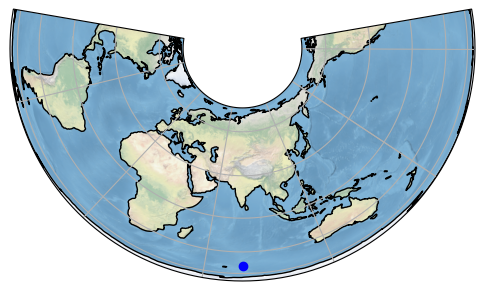

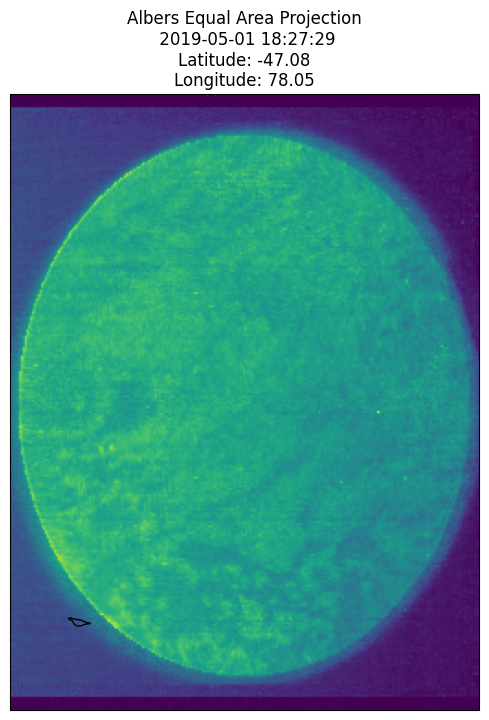

()

In [146]:
file='FAI_lv1_NIR_20190104_070011_070011_6.0.0.h5'
plotZoomedMap(file, 'aea', 'Albers Equal Area Projection')

In [147]:
plt.close('all')